# Bluesky API Likes to Followers Report
## Connor Kowalski, 10/19/26
**Hypothesis:** Does a higher like rate result in higher follower counts?
This data could be used to show if getting likes on your posts can turn in to followers and help your profile grow
**Vairables needed:** Like rate, follower count

## Endpoints
.GetProfiles .getAuthorFeed
## Why these endpoints?
These endpoints will contain the useful information because .GetProfiles will be used to get the follower count and post count vairiables. .getAuthorFeed will show the statistics like like rate to compare with the GetProfiles. This data is reliable because it comes from two vairables that almost directly coencide and answer an important question people have about the algorithm. Other data in getAuthorFeed can be used to view other factors that strengthen to the hypothesis. Outliar data could be missed because some accounts may only have a few followers as compared to more likes and skew the percentages. Hopefully readers can identify those and search them out.

In [1]:
import requests 
import pandas as pd

BASE = "https://public.api.bsky.app/xrpc"
accounts = ["nytimes.com", "atproto.com", "theonion.com", "npr.org", "washingtonpost.com", "espn.com", "nasa.gov", "reuters.com", "theverge.com"]

for account in accounts:
    response = requests.get(
        BASE + "/app.bsky.actor.getProfiles",
        params={"actors": accounts}, timeout=10
    )
    
print(response.status_code)

200


I'm using some of the same accounts as the example from in class on 10/14 because I was viewing the profiles and they each had a different level of posts and followers ect, which I think will help answer the hypothesis well. The other accounts are just some random ones.

In [2]:
data = response.json()
print(type(data))
print(data.keys())
print(len(data["profiles"]))
print(data["profiles"][0].keys())

<class 'dict'>
dict_keys(['profiles'])
8
dict_keys(['did', 'handle', 'displayName', 'avatar', 'associated', 'labels', 'createdAt', 'verification', 'description', 'indexedAt', 'banner', 'followersCount', 'followsCount', 'postsCount'])


Getting the json data and vairables

In [3]:
rows = []

for profile in data["profiles"]:
    handle = profile["handle"]

    response = requests.get(
        BASE + "/app.bsky.feed.getAuthorFeed",
        params={"actor": handle, "limit": 50, "filter": "posts_no_replies"},
        timeout=10
    )
    print(handle, response.status_code)

    data = response.json()

    likes = [item["post"]["likeCount"] for item in data["feed"] if "reason" not in item]

    rows.append({
        "account": handle,
        "followers": profile["followersCount"],
        "posts_sampled": len(likes),
        "avg_likes_per_post": sum(likes) / len(likes),
    })

rows

nytimes.com 200
atproto.com 200
theonion.com 200
npr.org 200
washingtonpost.com 200
espn.com 200
reuters.com 200
theverge.com 200


[{'account': 'nytimes.com',
  'followers': 1352974,
  'posts_sampled': 42,
  'avg_likes_per_post': 84.02380952380952},
 {'account': 'atproto.com',
  'followers': 121540,
  'posts_sampled': 45,
  'avg_likes_per_post': 83.17777777777778},
 {'account': 'theonion.com',
  'followers': 1359140,
  'posts_sampled': 47,
  'avg_likes_per_post': 1225.3617021276596},
 {'account': 'npr.org',
  'followers': 1013293,
  'posts_sampled': 50,
  'avg_likes_per_post': 159.96},
 {'account': 'washingtonpost.com',
  'followers': 874299,
  'posts_sampled': 48,
  'avg_likes_per_post': 41.541666666666664},
 {'account': 'espn.com',
  'followers': 303043,
  'posts_sampled': 50,
  'avg_likes_per_post': 109.52},
 {'account': 'reuters.com',
  'followers': 351090,
  'posts_sampled': 50,
  'avg_likes_per_post': 16.62},
 {'account': 'theverge.com',
  'followers': 378105,
  'posts_sampled': 37,
  'avg_likes_per_post': 23.675675675675677}]

Appends the nessecary vairables and data to the rows array. The large parameter for likes = is to skip the reposts on account because I saw they counted as posts, even if it wasn't their post being reposted, and the data from that post was going to the original poster, not the account reposted to, which the json didnt account for.

In [4]:
df = pd.DataFrame(rows)
df.head()

,account,followers,posts_sampled,avg_likes_per_post
0,nytimes.com,1352974,42,84.023810
1,atproto.com,121540,45,83.177778
2,theonion.com,1359140,47,1225.361702
3,npr.org,1013293,50,159.960000
4,washingtonpost.com,874299,48,41.541667


In [5]:
print(df.shape)
print(df.columns)
print(df.dtypes)
print(df.info())
print(df.describe())

(8, 4)
Index(['account', 'followers', 'posts_sampled', 'avg_likes_per_post'], dtype='str')
account                   str
followers               int64
posts_sampled           int64
avg_likes_per_post    float64
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   account             8 non-null      str    
 1   followers           8 non-null      int64  
 2   posts_sampled       8 non-null      int64  
 3   avg_likes_per_post  8 non-null      float64
dtypes: float64(1), int64(2), str(1)
memory usage: 388.0 bytes
None
          followers  posts_sampled  avg_likes_per_post
count  8.000000e+00       8.000000            8.000000
mean   7.191855e+05      46.125000          217.985079
std    4.933810e+05       4.642582          409.789875
min    1.215400e+05      37.000000           16.620000
25%    3.390782e+05      44.250000           37.0

wow! all kinds of awesome data thats stored in the data frame. Visualizing it here so I can know what to type and whats called what.

array([<Axes: title={'center': 'followers'}, xlabel='account'>,
       <Axes: title={'center': 'avg_likes_per_post'}, xlabel='account'>],
      dtype=object)

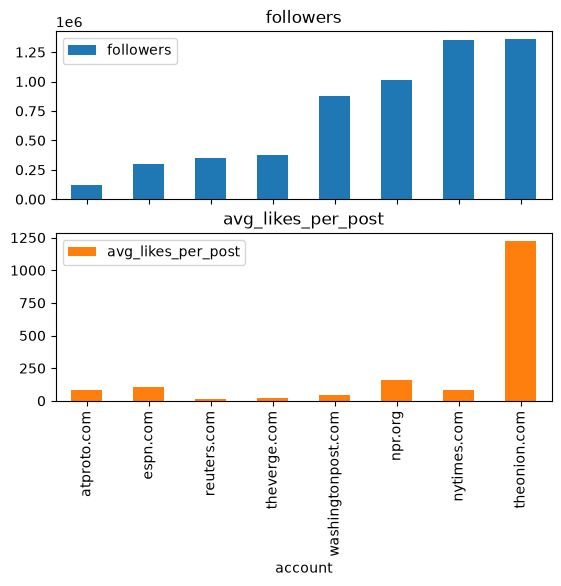

In [9]:
df.sort_values("followers").plot(
    x="account",
    y=["followers", "avg_likes_per_post"],
    kind="bar",
    subplots=True
)

## Conclusion:
There isn't actually too much relation between the two. The accounts where the bars are similar heights from blue to orange does show high engagement rates however, unlike NY Times followers to average likes rate. Overall, these two vairables alone can't really prove 